In [1]:
# Find-S Algorithm

dataset = [
    ["High", "Good", "Many", "Good", "Yes"],
    ["Medium", "Good", "Many", "Good", "Yes"],
    ["Low", "Poor", "None", "Poor", "No"],
    ["High", "Average", "Many", "Good", "Yes"],
    ["Medium", "Poor", "Few", "Average", "No"],
    ["High", "Good", "Few", "Good", "Yes"]
]

hypothesis = ["Ø", "Ø", "Ø", "Ø"]

print("Initial Hypothesis:", hypothesis)
print()

for example in dataset:

    attributes = example[:-1]
    target = example[-1]

    if target == "No":
        print("Negative Example - Skipped:", example)
        continue

    print("Positive Example - Evaluating:", example)

    if hypothesis[0] == "Ø":
        hypothesis = attributes.copy()

    else:
        for i in range(len(hypothesis)):
            if hypothesis[i] != attributes[i]:
                hypothesis[i] = "?"

    print("Updated Hypothesis:", hypothesis)
    print()

print("Final Hypothesis:", hypothesis)

Initial Hypothesis: ['Ø', 'Ø', 'Ø', 'Ø']

Positive Example - Evaluating: ['High', 'Good', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['High', 'Good', 'Many', 'Good']

Positive Example - Evaluating: ['Medium', 'Good', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['?', 'Good', 'Many', 'Good']

Negative Example - Skipped: ['Low', 'Poor', 'None', 'Poor', 'No']
Positive Example - Evaluating: ['High', 'Average', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['?', '?', 'Many', 'Good']

Negative Example - Skipped: ['Medium', 'Poor', 'Few', 'Average', 'No']
Positive Example - Evaluating: ['High', 'Good', 'Few', 'Good', 'Yes']
Updated Hypothesis: ['?', '?', '?', 'Good']

Final Hypothesis: ['?', '?', '?', 'Good']


Initial Hypothesis: ['0', '0', '0', '0']

Positive Example - Evaluating: ['High', 'Good', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['High', 'Good', 'Many', 'Good']

Positive Example - Evaluating: ['Medium', 'Good', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['?', 'Good', 'Many', 'Good']

Negative Example - Skipped: ['Low', 'Poor', 'None', 'Poor', 'No']
Positive Example - Evaluating: ['High', 'Average', 'Many', 'Good', 'Yes']
Updated Hypothesis: ['?', '?', 'Many', 'Good']

Negative Example - Skipped: ['Medium', 'Poor', 'Few', 'Average', 'No']
Positive Example - Evaluating: ['High', 'Good', 'Few', 'Good', 'Yes']
Updated Hypothesis: ['?', '?', '?', 'Good']

Final Hypothesis: ['?', '?', '?', 'Good']


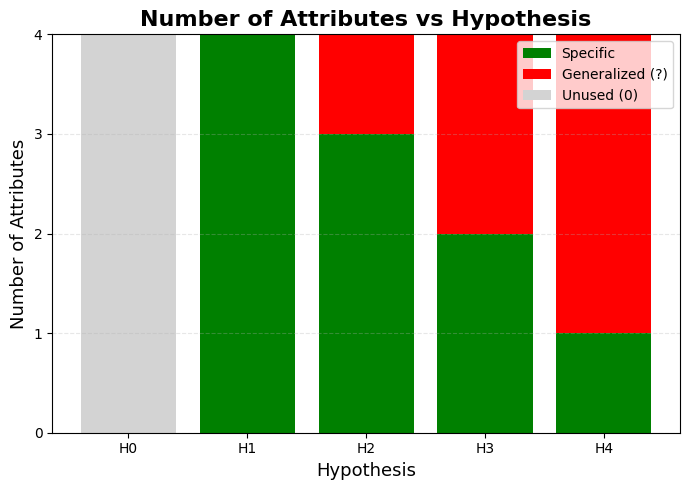

In [2]:
# Find-S Algorithm

import matplotlib.pyplot as plt


dataset = [
    ["High", "Good", "Many", "Good", "Yes"],
    ["Medium", "Good", "Many", "Good", "Yes"],
    ["Low", "Poor", "None", "Poor", "No"],
    ["High", "Average", "Many", "Good", "Yes"],
    ["Medium", "Poor", "Few", "Average", "No"],
    ["High", "Good", "Few", "Good", "Yes"]
]


attributes = dataset[0][:-1]

hypothesis = ["0"] * len(attributes)

history = []

print("Initial Hypothesis:", hypothesis)
print()


for example in dataset:

    example_attributes = example[:-1]
    target = example[-1]

    if target == "No":

        print("Negative Example - Skipped:", example)
        continue

    print("Positive Example - Evaluating:", example)

    if hypothesis[0] == "0":

        hypothesis = example_attributes.copy()

    else:

        for i in range(len(hypothesis)):

            if hypothesis[i] != example_attributes[i]:

                hypothesis[i] = "?"

    history.append(hypothesis.copy())

    print("Updated Hypothesis:", hypothesis)
    print()



print("Final Hypothesis:", hypothesis)



all_hypotheses = [["0"] * len(attributes)] + history


hypothesis_labels = [
    f"H{i}" for i in range(len(all_hypotheses))
]


unused_counts = []
specific_counts = []
generalized_counts = []


for hypothesis in all_hypotheses:

    unused = hypothesis.count("0")

    generalized = hypothesis.count("?")

    specific = len(hypothesis) - unused - generalized

    unused_counts.append(unused)

    specific_counts.append(specific)

    generalized_counts.append(generalized)



plt.figure(figsize=(7, 5))


plt.bar(
    hypothesis_labels,
    specific_counts,
    color="green",
    label="Specific"
)


plt.bar(
    hypothesis_labels,
    generalized_counts,
    bottom=specific_counts,
    color="red",
    label="Generalized (?)"
)

bottom_unused = [
    specific_counts[i] + generalized_counts[i]
    for i in range(len(hypothesis_labels))
]


plt.bar(
    hypothesis_labels,
    unused_counts,
    bottom=bottom_unused,
    color="lightgray",
    label="Unused (0)"
)


plt.title(
    "Number of Attributes vs Hypothesis",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Hypothesis",
    fontsize=13
)

plt.ylabel(
    "Number of Attributes",
    fontsize=13
)

plt.legend()


plt.yticks(
    range(0, len(attributes) + 1)
)


plt.grid(
    axis="y",
    linestyle="--",
    alpha=0.3
)

plt.tight_layout()

plt.show()

C:\Users\mithu\AppData\Local\Temp\ipykernel_1108\4024943862.py:9: FutureWarning: DataFrame.applymap has been deprecated. Use DataFrame.map instead.
  history_numeric = history_df.applymap(


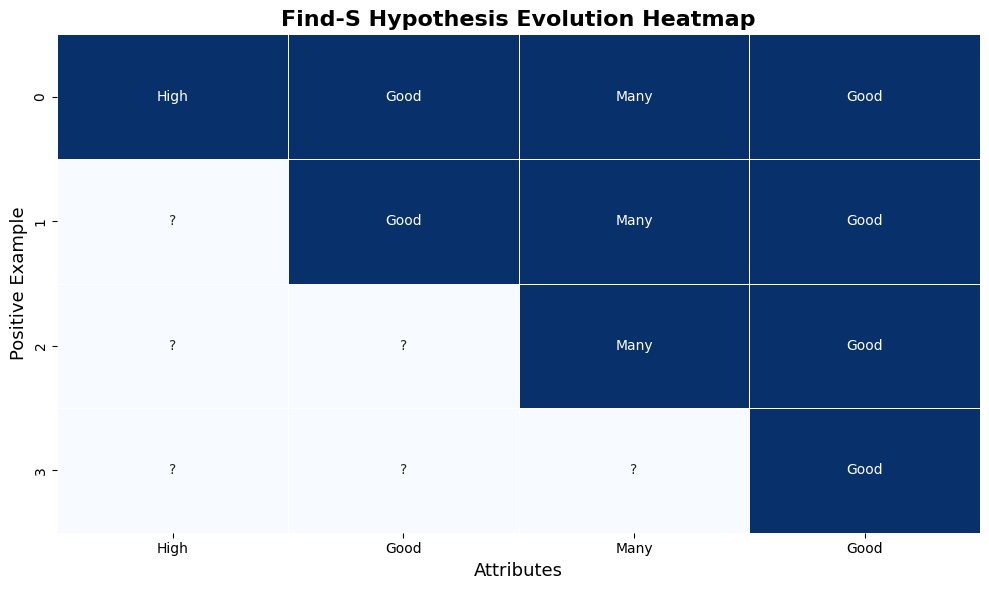

In [3]:

import seaborn as sns
import pandas as pd

history_df = pd.DataFrame(
    history,
    columns=attributes
)

history_numeric = history_df.applymap(
    lambda x: -1 if x == "0" else (0 if x == "?" else 1)
)

plt.figure(figsize=(10, 6))

sns.heatmap(
    history_numeric,
    annot=history_df,
    fmt="",
    cmap="Blues",
    cbar=False,
    linewidths=0.5
)

plt.title(
    "Find-S Hypothesis Evolution Heatmap",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel(
    "Attributes",
    fontsize=13
)

plt.ylabel(
    "Positive Example",
    fontsize=13
)

plt.tight_layout()
plt.show()